Project 1 : AI Customer Feedback Intelligence System

Import Libraries

In [4]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    silhouette_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

Download NLTK Data

In [5]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Victus\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Victus\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Victus\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

Load Dataset

The CSV is not stored in the repository. Download *Women's E-Commerce Clothing Reviews* (see `data/README.md`) and place it in `data/`.

In [6]:
DATA_PATH = "../data/Womens Clothing E-Commerce Reviews.csv"

df = pd.read_csv(DATA_PATH)

print(df.shape)
print(df.head())
print(df.columns)

(23486, 11)
   Unnamed: 0  Clothing ID  Age                    Title  \
0           0          767   33                      NaN   
1           1         1080   34                      NaN   
2           2         1077   60  Some major design flaws   
3           3         1049   50         My favorite buy!   
4           4          847   47         Flattering shirt   

                                         Review Text  Rating  Recommended IND  \
0  Absolutely wonderful - silky and sexy and comf...       4                1   
1  Love this dress!  it's sooo pretty.  i happene...       5                1   
2  I had such high hopes for this dress and reall...       3                0   
3  I love, love, love this jumpsuit. it's fun, fl...       5                1   
4  This shirt is very flattering to all due to th...       5                1   

   Positive Feedback Count   Division Name Department Name Class Name  
0                        0       Initmates        Intimate  Intimate

Select Important Columns

In [7]:
df = df[['Review Text', 'Rating', 'Class Name', 'Recommended IND']]

Remove Missing Values

In [8]:
df = df.dropna()

print(df.isnull().sum())
print(df.shape)

Review Text        0
Rating             0
Class Name         0
Recommended IND    0
dtype: int64
(22628, 4)


Remove Dublcates

In [9]:
df = df.drop_duplicates()

df = df.reset_index(drop=True)

print(df.shape)

(22622, 4)


Rename Columns

In [10]:
df = df.rename(columns={
    'Class Name': 'Product Category',
    'Recommended IND': 'Recommendation Indicator'
})

print(df.columns)

Index(['Review Text', 'Rating', 'Product Category',
       'Recommendation Indicator'],
      dtype='object')


Tokenization and Remove The Stopwords

In [11]:
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    tok = word_tokenize(text)
    tok = [word for word in tok if word.isalpha()]
    tok = [word for word in tok if word not in stop_words]
    return ' '.join(tok)

Clean Review Text

In [12]:
df['Clean Review'] = df['Review Text'].apply(clean_text)

print(df[['Review Text', 'Clean Review']].head())

                                         Review Text  \
0  Absolutely wonderful - silky and sexy and comf...   
1  Love this dress!  it's sooo pretty.  i happene...   
2  I had such high hopes for this dress and reall...   
3  I love, love, love this jumpsuit. it's fun, fl...   
4  This shirt is very flattering to all due to th...   

                                        Clean Review  
0        absolutely wonderful silky sexy comfortable  
1  love dress sooo pretty happened find store gla...  
2  high hopes dress really wanted work initially ...  
3  love love love jumpsuit fun flirty fabulous ev...  
4  shirt flattering due adjustable front tie perf...  


Create Sentiment

In [13]:
def get_sentiment(rating):
    if rating <= 2:
        return 'Negative'
    elif rating == 3:
        return 'Neutral'
    else:
        return 'Positive'

df['Sentiment'] = df['Rating'].apply(get_sentiment)

print(df[['Rating', 'Sentiment']].head(10))

   Rating Sentiment
0       4  Positive
1       5  Positive
2       3   Neutral
3       5  Positive
4       5  Positive
5       2  Negative
6       5  Positive
7       4  Positive
8       5  Positive
9       5  Positive


Split Data

In [14]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['Clean Review'],
    df['Sentiment'],
    test_size=0.2,
    random_state=42,
    stratify=df['Sentiment']
)

print(X_train_text.shape)
print(X_test_text.shape)

(18097,)
(4525,)


TF-IDF Vectorization

In [15]:
vectorizer = TfidfVectorizer(max_features=5000)

X_train = vectorizer.fit_transform(X_train_text)   # learn vocabulary + IDF from training data only
X_test = vectorizer.transform(X_test_text)         # only apply it to the test data

print(X_train.shape)
print(X_test.shape)

(18097, 5000)
(4525, 5000)


Logistic Regression Model

In [16]:
logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)

Evaluate Logistic Regression

In [17]:
logistic_accuracy = accuracy_score(y_test, logistic_pred)
logistic_macro_f1 = f1_score(y_test, logistic_pred, average='macro')

print('Logistic Regression Accuracy:', logistic_accuracy)
print('Logistic Regression Macro F1:', logistic_macro_f1)
print(classification_report(y_test, logistic_pred))

Logistic Regression Accuracy: 0.8209944751381215
Logistic Regression Macro F1: 0.5700633461740892
              precision    recall  f1-score   support

    Negative       0.61      0.41      0.49       474
     Neutral       0.44      0.23      0.30       565
    Positive       0.87      0.97      0.92      3486

    accuracy                           0.82      4525
   macro avg       0.64      0.54      0.57      4525
weighted avg       0.79      0.82      0.80      4525



Random Forest Model

In [18]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

random_forest_pred = random_forest_model.predict(X_test)

Evaluate Random Forest

In [19]:
random_forest_accuracy = accuracy_score(y_test, random_forest_pred)
random_forest_macro_f1 = f1_score(y_test, random_forest_pred, average='macro')

print('Random Forest Accuracy:', random_forest_accuracy)
print('Random Forest Macro F1:', random_forest_macro_f1)
print(classification_report(y_test, random_forest_pred))

Random Forest Accuracy: 0.7832044198895027
Random Forest Macro F1: 0.37938979136032586
              precision    recall  f1-score   support

    Negative       0.57      0.13      0.21       474
     Neutral       0.47      0.02      0.05       565
    Positive       0.79      1.00      0.88      3486

    accuracy                           0.78      4525
   macro avg       0.61      0.38      0.38      4525
weighted avg       0.73      0.78      0.71      4525



Handling Class Imbalance

Positive reviews are ~77% of the data, so accuracy alone is misleading. Here we test whether class weights improve recall on the Negative and Neutral classes.

In [20]:
logistic_balanced = LogisticRegression(max_iter=1000, class_weight='balanced')
logistic_balanced.fit(X_train, y_train)
logistic_balanced_pred = logistic_balanced.predict(X_test)

random_forest_balanced = RandomForestClassifier(
    n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced'
)
random_forest_balanced.fit(X_train, y_train)
random_forest_balanced_pred = random_forest_balanced.predict(X_test)

for name, pred in [
    ('Logistic Regression (balanced)', logistic_balanced_pred),
    ('Random Forest (balanced)', random_forest_balanced_pred),
]:
    print(name)
    print('Accuracy:', accuracy_score(y_test, pred))
    print('Macro F1:', f1_score(y_test, pred, average='macro'))
    print(classification_report(y_test, pred))

Logistic Regression (balanced)
Accuracy: 0.7703867403314917
Macro F1: 0.5974089027514085
              precision    recall  f1-score   support

    Negative       0.44      0.57      0.50       474
     Neutral       0.33      0.49      0.40       565
    Positive       0.95      0.84      0.89      3486

    accuracy                           0.77      4525
   macro avg       0.58      0.64      0.60      4525
weighted avg       0.82      0.77      0.79      4525

Random Forest (balanced)
Accuracy: 0.7865193370165746
Macro F1: 0.39083671136523873
              precision    recall  f1-score   support

    Negative       0.64      0.15      0.24       474
     Neutral       0.54      0.02      0.05       565
    Positive       0.79      1.00      0.88      3486

    accuracy                           0.79      4525
   macro avg       0.66      0.39      0.39      4525
weighted avg       0.74      0.79      0.71      4525



Confusion Matrices

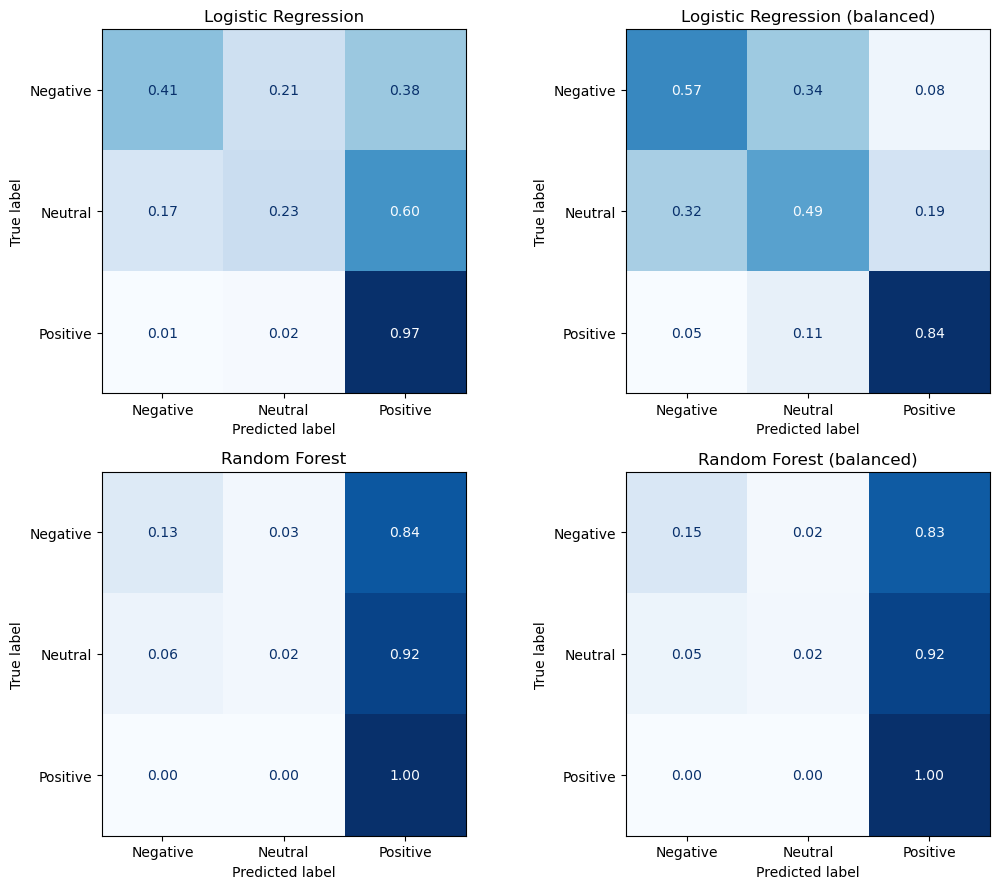

In [21]:
preds_dict = {
    'Logistic Regression': logistic_pred,
    'Logistic Regression (balanced)': logistic_balanced_pred,
    'Random Forest': random_forest_pred,
    'Random Forest (balanced)': random_forest_balanced_pred
}

fig, ax = plt.subplots(2, 2, figsize=(11, 9))
ax_list = ax.flatten()

for i, (title, pred) in enumerate(preds_dict.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        display_labels=['Negative', 'Neutral', 'Positive'],
        normalize='true',
        cmap='Blues',
        values_format='.2f',
        ax=ax_list[i],
        colorbar=False
    )
    ax_list[i].set_title(title)

plt.tight_layout()
plt.show()

Select Negative Reviews

In [22]:
negative_reviews = df[df['Sentiment'] == 'Negative'].copy()

print(negative_reviews.shape)

(2369, 6)


Convert Negative Reviews to TF-IDF

In [23]:
negative_X = vectorizer.transform(negative_reviews['Clean Review'])

print(negative_X.shape)

(2369, 5000)


K-Means Clustering

In [24]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

negative_reviews['Cluster'] = kmeans.fit_predict(negative_X)

print(negative_reviews[['Review Text', 'Cluster']].head())

c:\Users\Victus\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:131: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Victus\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "c:\Users\Victus\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Victus\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^

                                          Review Text  Cluster
5   I love tracy reese dresses, but this one is no...        2
22  First of all, this is not pullover styling. th...        0
26  I have been waiting for this sweater coat to s...        0
33  I ordered this 3 months ago, and it finally ca...        0
56  I am pregnant and i thought this would be a gr...        3


Find Common Words in Each Cluster

In [25]:
feature_names = vectorizer.get_feature_names_out()

for cluster_number in range(5):
    cluster_data = negative_reviews[
        negative_reviews['Cluster'] == cluster_number
    ]

    cluster_X = vectorizer.transform(cluster_data['Clean Review'])

    cluster_words = np.asarray(cluster_X.sum(axis=0)).ravel()

    top_words = cluster_words.argsort()[-10:][::-1]

    print('Cluster', cluster_number)
    print(feature_names[top_words])

Cluster 0
['like' 'looked' 'looks' 'look' 'back' 'fabric' 'cheap' 'sweater' 'model'
 'picture']
Cluster 1
['shirt' 'back' 'would' 'fabric' 'boxy' 'like' 'loved' 'thin' 'short'
 'returning']
Cluster 2
['dress' 'like' 'would' 'fabric' 'back' 'disappointed' 'material' 'really'
 'size' 'fit']
Cluster 3
['quality' 'fabric' 'return' 'would' 'even' 'pants' 'one' 'could' 'thin'
 'back']
Cluster 4
['top' 'small' 'size' 'ordered' 'would' 'fit' 'large' 'like' 'way'
 'really']


Sanity-check the number of clusters

k=5 was chosen up front. Silhouette scores for several values of k show how well-separated the clusters are; scores on sparse TF-IDF text are usually low, so treat the themes below as exploratory.

In [26]:
silhouette_scores = {}
for k in range(2, 9):
    labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(negative_X)
    silhouette_scores[k] = round(silhouette_score(negative_X, labels), 4)

print(silhouette_scores)

{2: 0.0042, 3: 0.005, 4: 0.0058, 5: 0.0062, 6: 0.0064, 7: 0.007, 8: 0.0077}


Sentiment Distribution

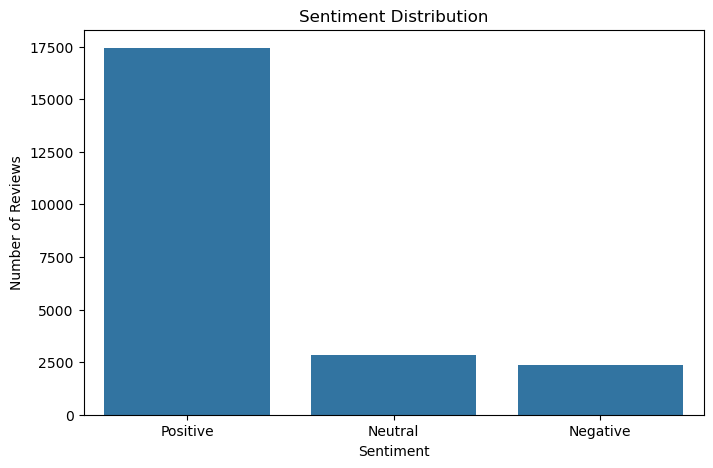

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Sentiment')

plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.show()

Rating Distribution

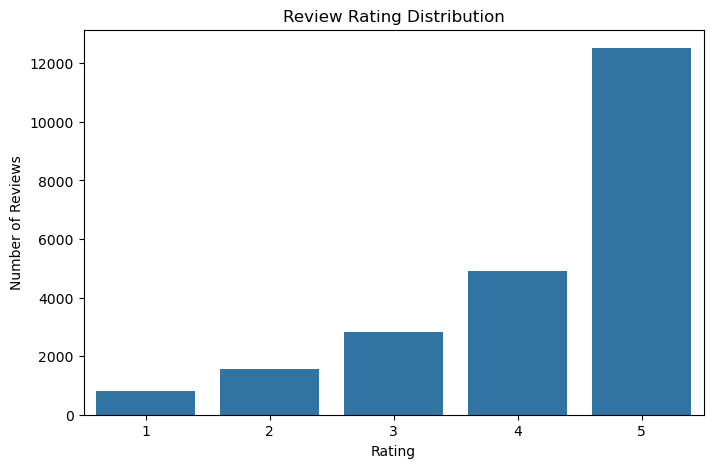

In [28]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='Rating')

plt.title('Review Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')

plt.show()

Most Common Words

In [29]:
words = df['Clean Review'].str.split().explode()

common_words = words.value_counts().head(15)

print(common_words)

Clean Review
dress      10495
love        8931
size        8697
top         7346
fit         7268
like        7006
wear        6415
great       6096
would       5425
fabric      4777
small       4561
color       4560
look        4018
really      3923
ordered     3831
Name: count, dtype: int64


Plot Most Common Words

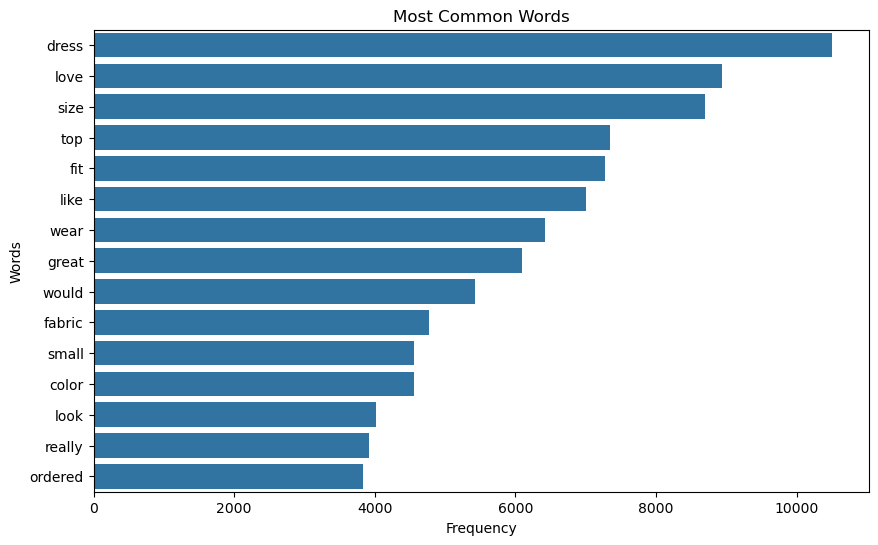

In [30]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=common_words.values,
    y=common_words.index
)

plt.title('Most Common Words')
plt.xlabel('Frequency')
plt.ylabel('Words')

plt.show()

Cluster Analysis

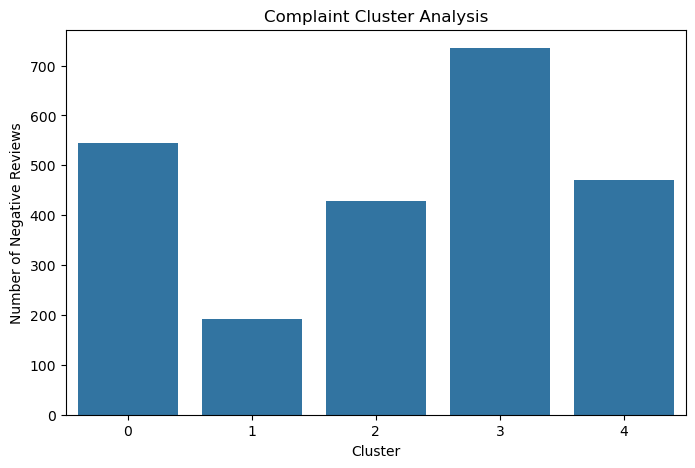

In [31]:
plt.figure(figsize=(8, 5))

sns.countplot(data=negative_reviews, x='Cluster')

plt.title('Complaint Cluster Analysis')
plt.xlabel('Cluster')
plt.ylabel('Number of Negative Reviews')

plt.show()

Negative Reviews by Product Category

In [32]:
negative_reviews.groupby('Product Category').size().sort_values(ascending=False)

Product Category
Dresses       680
Knits         498
Blouses       343
Sweaters      151
Pants         122
Fine gauge    104
Jeans          85
Skirts         85
Jackets        72
Lounge         46
Swim           38
Outerwear      36
Shorts         25
Sleep          23
Trend          21
Legwear        16
Intimates      14
Layering       10
dtype: int64

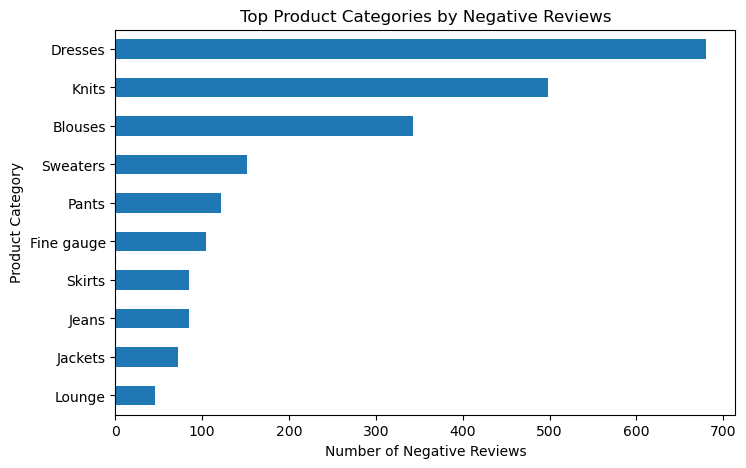

In [33]:
negative_reviews['Product Category'].value_counts().head(10).plot(
    kind='barh', figsize=(8,5)
)
plt.title('Top Product Categories by Negative Reviews')
plt.xlabel('Number of Negative Reviews')
plt.gca().invert_yaxis()
plt.show()

Average Rating

In [34]:
print('Average Rating:', df['Rating'].mean())

Average Rating: 4.183007691627619


Count Sentiments

In [35]:
print('Positive Reviews:', (df['Sentiment'] == 'Positive').sum())
print('Neutral Reviews:', (df['Sentiment'] == 'Neutral').sum())
print('Negative Reviews:', (df['Sentiment'] == 'Negative').sum())

Positive Reviews: 17430
Neutral Reviews: 2823
Negative Reviews: 2369


Compare Models

In [36]:
results = pd.DataFrame(
    [
        {
            'model': name,
            'accuracy': accuracy_score(y_test, pred),
            'macro_f1': f1_score(y_test, pred, average='macro'),
            'recall_negative': classification_report(y_test, pred, output_dict=True)['Negative']['recall'],
            'recall_neutral': classification_report(y_test, pred, output_dict=True)['Neutral']['recall'],
            'recall_positive': classification_report(y_test, pred, output_dict=True)['Positive']['recall'],
        }
        for name, pred in preds_dict.items()
    ]
).round(4)

results

,model,accuracy,macro_f1,recall_negative,recall_neutral,recall_positive
0,Logistic Regression,0.8210,0.5701,0.4135,0.2283,0.9725
1,Logistic Regression (balanced),0.7704,0.5974,0.5738,0.4903,0.8425
2,Random Forest,0.7832,0.3794,0.1287,0.0248,0.9951
3,Random Forest (balanced),0.7865,0.3908,0.1498,0.0248,0.9966


Save Outputs (metrics, cluster summary, cleaned dataset)

In [37]:
from pathlib import Path

OUTPUT_DIR = Path('../outputs')
OUTPUT_DIR.mkdir(exist_ok=True)

results.to_csv(OUTPUT_DIR / 'model_metrics.csv', index=False)

cluster_summary = negative_reviews.groupby('Cluster').size().rename('reviews').reset_index()
cluster_summary.to_csv(OUTPUT_DIR / 'cluster_summary.csv', index=False)

processed_dir = Path('../data/processed')
processed_dir.mkdir(parents=True, exist_ok=True)
df.to_csv(processed_dir / 'cleaned_customer_reviews.csv', index=False)

Save the Inference Pipeline

The saved object includes the text-cleaning step, the TF-IDF vectorizer and the classifier, so it accepts **raw review text**. Only load `.joblib`/`.pkl` files that you created yourself.

In [38]:
import sys
import joblib
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

sys.path.insert(0, str(Path('..').resolve()))
from src.preprocessing import clean_texts

sentiment_pipeline = Pipeline([
    ('clean', FunctionTransformer(clean_texts)),
    ('tfidf', vectorizer),
    ('clf', logistic_model),
])

Path('../models').mkdir(exist_ok=True)
joblib.dump(sentiment_pipeline, '../models/sentiment_pipeline.joblib')

print(sentiment_pipeline.predict([
    'The fabric feels cheap and thin.',
    'I love this dress!',
]))

['Negative' 'Positive']
